In [1]:
# ============================================================
# Predicción de abandono de clientes — IBM Telco Customer Churn
# Versión didáctica: comparación simple de cinco modelos
# Documentación completa: DOCUMENTACION.md
# Kernel: Python 3.15 (Telco Churn)
# ============================================================

# 1. Importaciones y configuración
# Utilidades estándar: versión de Python y rutas de archivos
import sys
from pathlib import Path

# Gráficos (matplotlib y seaborn) y manejo de tablas (pandas)
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# Librerías de Machine Learning (scikit-learn y XGBoost) y sus herramientas
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer  # aplica un tratamiento distinto a cada grupo de variables
from sklearn.dummy import DummyClassifier  # modelo de referencia (siempre dice «no abandona»)
from sklearn.ensemble import RandomForestClassifier  # Modelo 4: Random Forest
from sklearn.impute import SimpleImputer  # rellena valores vacíos
from sklearn.linear_model import LogisticRegression  # Modelo 1: regresión logística
from sklearn.metrics import (  # métricas para evaluar los modelos
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split  # divide los datos en entrenamiento, validación y prueba
from sklearn.neighbors import KNeighborsClassifier  # Modelo 2: KNN
from sklearn.pipeline import Pipeline  # encadena preprocesamiento y modelo en un solo objeto
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # convierte texto en 0/1 y pone los números en la misma escala
from sklearn.tree import DecisionTreeClassifier  # Modelo 3: árbol de decisión
from xgboost import XGBClassifier  # Modelo 5: XGBoost

# Semilla: permite repetir siempre la misma división de datos
RANDOM_STATE = 42
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")  # ruta donde debe estar el archivo CSV
TARGET = "Churn"  # nombre de la columna que se quiere predecir

pd.set_option("display.max_columns", 40)  # muestra hasta 40 columnas al imprimir tablas
pd.set_option("display.width", 160)  # ancho de impresión de las tablas
sns.set_theme(style="whitegrid", palette="deep")  # estilo visual de los gráficos
plt.rcParams["figure.dpi"] = 110  # resolución de las figuras

# Muestra las versiones de las librerías usadas (sirve para repetir el resultado)
print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"XGBoost     : {xgboost.__version__}")

Python      : 3.15.2
pandas      : 3.1.1
scikit-learn: 1.9.1
XGBoost     : 3.4.1


> **Cómo está organizado este notebook.** Las celdas numeradas del **1 al 17** son la versión base del equipo:
> misma lógica y mismos resultados, con los comentarios ampliados para que se puedan seguir sin mirar la teoría.
> Las secciones marcadas como **«Ampliación»** se agregaron para completar lo que pide la rúbrica: descarga de datos,
> EDA ampliado, ROC-AUC, validación cruzada, ajuste de hiperparámetros, cumplimiento de metas e interpretación de variables.
> Todas las ampliaciones reutilizan las variables ya creadas (`X_train`, `X_val`, `X_test`, `modelos`, `preprocesador`, ...).

In [2]:
# Ampliación 0: datos e importaciones adicionales
# Descarga automática del CSV si no existe (así funciona en Google Colab sin subir archivos).
# Si prefieres usar tu propio archivo, súbelo a la carpeta data/ con el mismo nombre.
# Importaciones adicionales: descarga de datos, clonado de modelos, validación y avisos
import urllib.request
import warnings  # permite silenciar un aviso interno de scikit-learn (Ampliación 4)
from sklearn.base import clone  # crea copias sin entrenar de un modelo
from sklearn.metrics import roc_auc_score, roc_curve  # ROC-AUC y puntos de la curva ROC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate  # búsqueda de hiperparámetros y validación cruzada

DATA_PATH.parent.mkdir(exist_ok=True)  # crea la carpeta data/ si no existe
if not DATA_PATH.exists():  # solo descarga si el archivo aún no está
    urllib.request.urlretrieve(  # descarga el CSV desde el repositorio público de IBM
        "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
        DATA_PATH,
    )
# Confirma qué archivo se usará y su tamaño
print(f"Archivo de datos: {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)")

Archivo de datos: data\WA_Fn-UseC_-Telco-Customer-Churn.csv (977,501 bytes)


In [3]:
# 2. Cargar los datos
df = pd.read_csv(DATA_PATH)  # lee el archivo CSV en una tabla (DataFrame)

# Muestra cuántos clientes (filas) y columnas hay
print(f"Clientes: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()  # muestra las primeras 5 filas para ver cómo son los datos

Clientes: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# 3. Revisar la variable objetivo
# Churn = Yes significa que el cliente abandonó.
conteo = df[TARGET].value_counts().rename(index={"No": "No abandona", "Yes": "Abandona"})  # cuenta cuántos clientes hay en cada clase de Churn
tabla_objetivo = pd.DataFrame(  # arma una tabla con la cantidad y el porcentaje de cada clase
    {
        "clientes": conteo,
        "porcentaje": (conteo / len(df) * 100).round(2),
    }
)
print(tabla_objetivo.to_string())  # imprime la tabla

# TotalCharges viene como texto porque 11 registros están vacíos.
no_numericos = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()  # True donde TotalCharges no se puede convertir a número
# Cuenta y muestra los registros con TotalCharges vacío (todos tienen antigüedad 0)
print(f"\nTotalCharges vacío: {no_numericos.sum()} registros")
print(df.loc[no_numericos, ["tenure", "TotalCharges"]].to_string(index=False))

             clientes  porcentaje
Churn                            
No abandona      5174       73.46
Abandona         1869       26.54

TotalCharges vacío: 11 registros
 tenure TotalCharges
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             


In [5]:
# 4. Limpiar los datos
# - TotalCharges: de texto a número.
# - Churn: de Yes/No a 1/0, porque los modelos necesitan números.
df = df.copy()  # trabaja sobre una copia para no alterar el original
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # convierte a número; los vacíos pasan a NaN
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})  # No -> 0 (permanece), Yes -> 1 (abandona)

# Los 11 vacíos son clientes con antigüedad 0 (aún no tienen facturación).
# Si apareciera otro caso, hay que revisarlo antes de continuar.
faltantes = df["TotalCharges"].isna()  # marca los clientes con TotalCharges vacío
assert (df.loc[faltantes, "tenure"] == 0).all(), "Revisar TotalCharges faltante"  # detiene el código si algún vacío NO tiene antigüedad 0

# Resumen de la limpieza
print(f"TotalCharges vacío: {faltantes.sum()} casos, todos con antigüedad 0")
print(f"Tasa de abandono: {df[TARGET].mean():.2%}")

TotalCharges vacío: 11 casos, todos con antigüedad 0
Tasa de abandono: 26.54%


In [6]:
# 5. Dividir los datos en tres partes
# - entrenamiento: el modelo aprende
# - validación: comparamos los cinco modelos y elegimos uno
# - prueba: comprobamos el resultado final (se usa una sola vez)
#
# customerID se excluye porque identifica al cliente, no describe su comportamiento.
X = df.drop(columns=["customerID", TARGET])  # X = variables que explican (todas menos el ID y Churn)
y = df[TARGET]  # y = lo que se quiere predecir (Churn)

# Primero apartamos el 20 % de prueba
X_resto, X_test, y_resto, y_test = train_test_split(  # stratify=y mantiene el mismo % de abandono en cada parte; random_state fija la semilla
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Del 80 % restante, apartamos un 25 % para validación (20 % del total)
X_train, X_val, y_train, y_val = train_test_split(  # 25 % del 80 % = 20 % del total para validación (queda 60 % para entrenar)
    X_resto,
    y_resto,
    test_size=0.25,
    stratify=y_resto,
    random_state=RANDOM_STATE,
)

# Verifica el tamaño y el % de abandono de cada conjunto (deben ser casi iguales)
print(f"Entrenamiento: {len(X_train):,} clientes | abandono {y_train.mean():.2%}")
print(f"Validación   : {len(X_val):,} clientes | abandono {y_val.mean():.2%}")
print(f"Prueba       : {len(X_test):,} clientes | abandono {y_test.mean():.2%}")

Entrenamiento: 4,225 clientes | abandono 26.53%
Validación   : 1,409 clientes | abandono 26.54%
Prueba       : 1,409 clientes | abandono 26.54%


In [7]:
# 6. Explorar los datos (solo entrenamiento)
# Como Churn vale 0 o 1, su promedio en un grupo es su tasa de abandono.
train = X_train.assign(Churn=y_train)  # une X_train con Churn para poder agrupar y calcular tasas


def tasa_por(columna):  # función: tasa de abandono para cada valor de una variable
    tabla = (
        train.groupby(columna, observed=True)["Churn"]  # agrupa a los clientes por los valores de la variable
        .agg(clientes="size", tasa="mean")  # cuenta clientes y promedia Churn (= tasa de abandono)
        .sort_values("tasa", ascending=False)  # ordena de mayor a menor abandono
    )
    tabla["tasa"] = (tabla["tasa"] * 100).round(1)  # pasa la tasa a porcentaje con 1 decimal
    return tabla


for variable in ["Contract", "InternetService", "PaymentMethod"]:  # imprime la tasa de abandono de tres variables clave
    print(f"\nTasa de abandono por {variable} (%):")
    print(tasa_por(variable).to_string())


Tasa de abandono por Contract (%):
                clientes  tasa
Contract                      
Month-to-month      2326  43.1
One year             865  10.8
Two year            1034   2.5

Tasa de abandono por InternetService (%):
                 clientes  tasa
InternetService                
Fiber optic          1843  42.3
DSL                  1474  18.7
No                    908   7.3

Tasa de abandono por PaymentMethod (%):
                           clientes  tasa
PaymentMethod                            
Electronic check               1410  45.6
Mailed check                    980  19.5
Bank transfer (automatic)       926  16.2
Credit card (automatic)         909  15.1


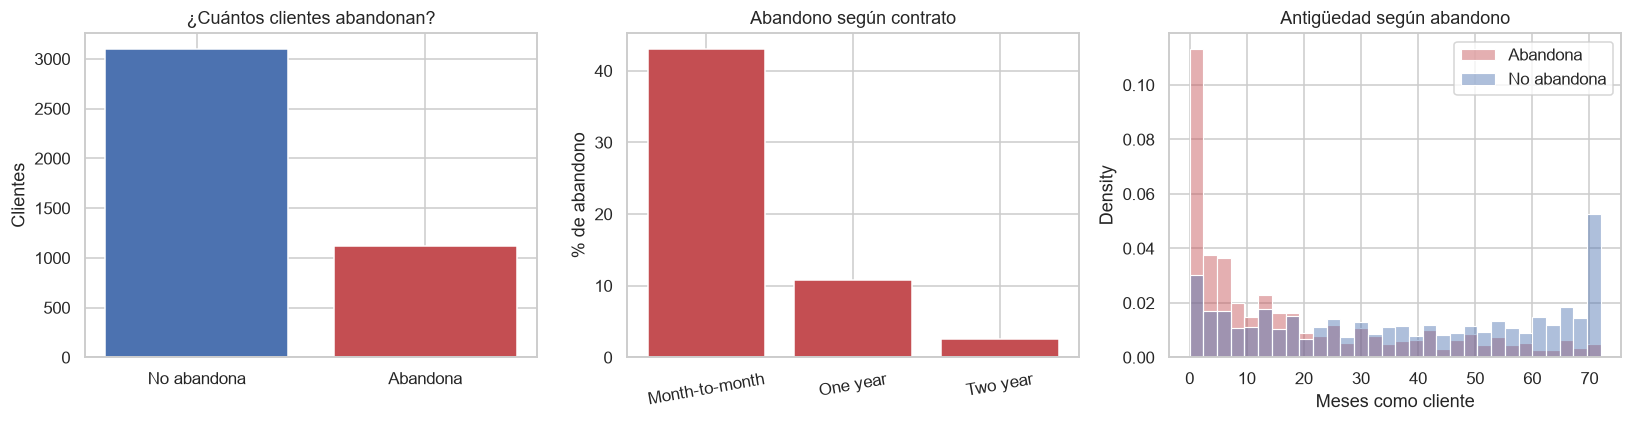

In [8]:
# Figura 1: cuántos abandonan, por contrato y según antigüedad
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # figura con 3 gráficos en una fila

# Cuántos clientes hay en cada clase
conteo = train["Churn"].map({0: "No abandona", 1: "Abandona"}).value_counts()
axes[0].bar(conteo.index, conteo.values, color=["#4C72B0", "#C44E52"])  # gráfico 1: barras con la cantidad de clientes de cada clase
axes[0].set_title("¿Cuántos clientes abandonan?")
axes[0].set_ylabel("Clientes")

# Tasa de abandono según el tipo de contrato
tasa_contrato = tasa_por("Contract")
axes[1].bar(tasa_contrato.index, tasa_contrato["tasa"], color="#C44E52")  # gráfico 2: barras con la tasa de abandono por contrato
axes[1].set_title("Abandono según contrato")
axes[1].set_ylabel("% de abandono")
axes[1].tick_params(axis="x", rotation=10)  # inclina un poco las etiquetas del eje X

# Distribución de la antigüedad en cada grupo
sns.histplot(  # gráfico 3: histograma de la antigüedad (density permite comparar grupos de distinto tamaño)
    data=train,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.45,
    ax=axes[2],
)
axes[2].set_title("Antigüedad según abandono")
axes[2].set_xlabel("Meses como cliente")
axes[2].legend(title="", labels=["Abandona", "No abandona"])  # nombres de los dos grupos

fig.tight_layout()  # acomoda los gráficos sin que se superpongan
plt.show()  # muestra la figura

## Ampliación 1 – EDA ampliado (solo entrenamiento)
Se revisan la antigüedad, el soporte técnico, la seguridad en línea, la factura electrónica y los adultos mayores, que no estaban en la exploración inicial.

In [9]:
# Ampliación 1: más variables y rangos de antigüedad (se trabaja sobre una copia para no alterar `train`)
eda = train.copy()
eda["Antigüedad (meses)"] = pd.cut(eda["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])  # agrupa la antigüedad en 4 rangos de meses

tablas_eda = {}  # diccionario donde se guardan las tablas para reutilizarlas en el gráfico
for variable in ["Antigüedad (meses)", "TechSupport", "OnlineSecurity", "PaperlessBilling", "SeniorCitizen"]:  # calcula la tasa de abandono de cada variable
    tablas_eda[variable] = eda.groupby(variable, observed=True)["Churn"].agg(clientes="size", tasa="mean")  # cuenta clientes y calcula la tasa de abandono por cada valor
    tablas_eda[variable]["tasa"] = (tablas_eda[variable]["tasa"] * 100).round(1)  # tasa en porcentaje con 1 decimal
    print(f"\nTasa de abandono por {variable} (%):")
    print(tablas_eda[variable].to_string())

# Mediana de antigüedad y cargo mensual de quienes permanecen (0) y abandonan (1)
print("\nMediana por grupo (0 = permanece, 1 = abandona):")
print(eda.groupby("Churn")[["tenure", "MonthlyCharges"]].median().round(2).to_string())
# Correlación de cada variable numérica con el abandono (cerca de 0 = poca relación)
print("\nCorrelación con el abandono:")
print(eda[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr()["Churn"].drop("Churn").round(3).to_string())


Tasa de abandono por Antigüedad (meses) (%):
                    clientes  tasa
Antigüedad (meses)                
0-12                    1318  47.3
13-24                    629  29.3
25-48                    940  19.8
49-72                   1338   9.6

Tasa de abandono por TechSupport (%):
                     clientes  tasa
TechSupport                        
No                       2082  41.8
No internet service       908   7.3
Yes                      1235  15.0

Tasa de abandono por OnlineSecurity (%):
                     clientes  tasa
OnlineSecurity                     
No                       2103  42.0
No internet service       908   7.3
Yes                      1214  14.1

Tasa de abandono por PaperlessBilling (%):
                  clientes  tasa
PaperlessBilling                
No                    1701  16.2
Yes                   2524  33.5

Tasa de abandono por SeniorCitizen (%):
               clientes  tasa
SeniorCitizen                
0                  3534  2

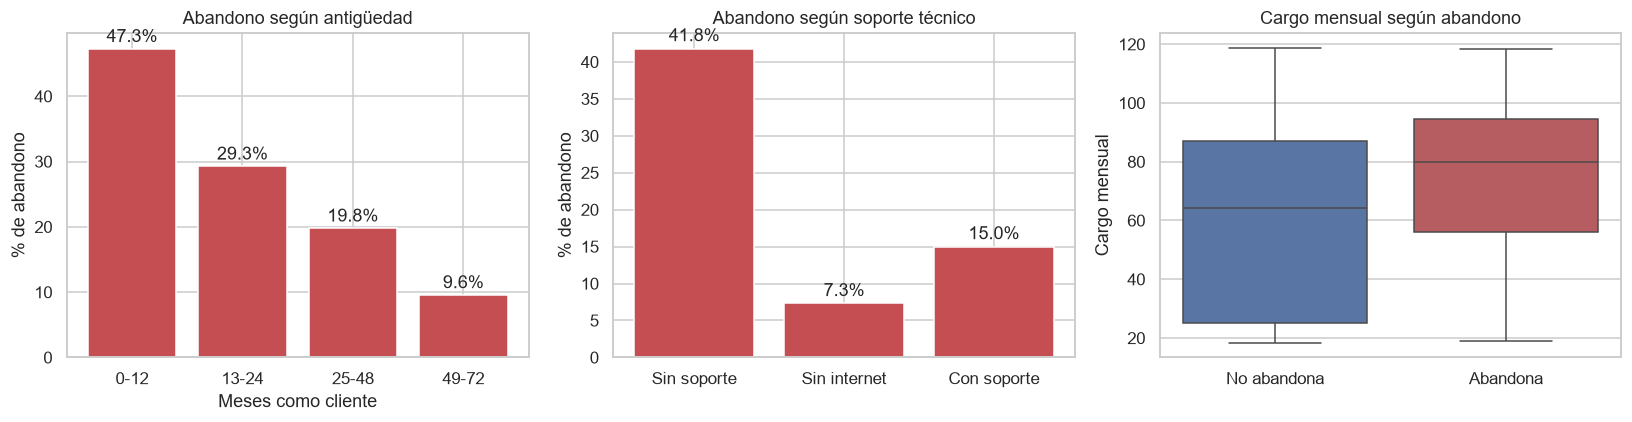

In [10]:
# Figura 1b: antigüedad, soporte técnico y cargo mensual frente al abandono
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

t = tablas_eda["Antigüedad (meses)"]  # datos del gráfico 1
axes[0].bar(t.index.astype(str), t["tasa"], color="#C44E52")  # gráfico 1: tasa de abandono por rango de antigüedad
axes[0].set_title("Abandono según antigüedad")
axes[0].set_ylabel("% de abandono")
axes[0].set_xlabel("Meses como cliente")
for i, v in enumerate(t["tasa"]):  # escribe el % encima de cada barra
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center")

t = tablas_eda["TechSupport"]  # datos del gráfico 2
valores = [t.loc["No", "tasa"], t.loc["No internet service", "tasa"], t.loc["Yes", "tasa"]]
axes[1].bar(["Sin soporte", "Sin internet", "Con soporte"], valores, color="#C44E52")  # gráfico 2: tasa de abandono según soporte técnico
axes[1].set_title("Abandono según soporte técnico")
axes[1].set_ylabel("% de abandono")
for i, v in enumerate(valores):  # escribe el % encima de cada barra
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")

sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", hue="Churn", palette={0: "#4C72B0", 1: "#C44E52"}, legend=False, ax=axes[2])  # gráfico 3: cargo mensual de quienes permanecen (0) y abandonan (1)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["No abandona", "Abandona"])  # reemplaza 0 y 1 por nombres claros
axes[2].set_title("Cargo mensual según abandono")
axes[2].set_xlabel("")
axes[2].set_ylabel("Cargo mensual")
fig.tight_layout()  # acomoda los gráficos
plt.show()  # muestra la figura

In [11]:
# 7. Preparar las variables
# Los modelos no entienden texto ("DSL", "Two year"...), así que:
# - variables numéricas: rellenamos huecos y las ponemos en la misma escala
# - variables de texto: las convertimos en columnas de 0 y 1 (one-hot)
# - TotalCharges vacío: lo rellenamos con 0 (cliente nuevo sin facturación)
NUMERICAS = ["tenure", "MonthlyCharges"]  # variables numéricas que se escalan
FACTURACION = ["TotalCharges"]  # TotalCharges va aparte porque sus vacíos se rellenan con 0
CATEGORICAS = [c for c in X_train.columns if c not in NUMERICAS + FACTURACION]  # todas las demás variables (texto o binarias) se tratan como categorías

preprocesador = ColumnTransformer(  # aplica un tratamiento distinto a cada grupo de variables
    [
        (
            "numericas",  # grupo 1: tenure y MonthlyCharges
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="median")),  # rellena huecos con la mediana
                    ("escalar", StandardScaler()),  # pone la variable en una escala comparable (promedio 0, desviación 1)
                ]
            ),
            NUMERICAS,
        ),
        (
            "facturacion",  # grupo 2: TotalCharges
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="constant", fill_value=0)),  # rellena huecos con 0 (cliente nuevo sin facturación)
                    ("escalar", StandardScaler()),  # misma escala que las demás variables numéricas
                ]
            ),
            FACTURACION,
        ),
        (
            "categoricas",  # grupo 3: variables de texto
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="most_frequent")),  # rellena huecos con el valor más frecuente
                    ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),  # convierte cada categoría en una columna de 0 y 1 (ignora categorías nuevas)
                ]
            ),
            CATEGORICAS,
        ),
    ]
)

# Resumen de los grupos de variables
print(f"Variables numéricas   : {NUMERICAS + FACTURACION}")
print(f"Variables categóricas : {len(CATEGORICAS)}")

Variables numéricas   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas : 16


In [12]:
# 8. Referencia: un modelo que siempre dice "no abandona"
# Demuestra por qué la exactitud (accuracy) engaña: acierta ~73 %
# pero no detecta ni un solo abandono.
referencia = DummyClassifier(strategy="most_frequent")  # modelo que siempre predice la clase más frecuente
referencia.fit(X_train, y_train)  # «entrena» con los datos de entrenamiento
prediccion = referencia.predict(X_val)  # predice sobre validación

# Accuracy alto pero recall 0: no detecta ningún abandono
print(f"Accuracy : {accuracy_score(y_val, prediccion):.3f}")
print(f"Recall   : {recall_score(y_val, prediccion, zero_division=0):.3f}")

Accuracy : 0.735
Recall   : 0.000


In [13]:
# 9. Modelo 1: Regresión logística
# Combina las variables con pesos. Es el modelo más fácil de interpretar.
modelo_lr = Pipeline(  # Pipeline = preprocesamiento + modelo en un solo objeto
    [
        ("preprocesador", preprocesador),  # paso 1: preparar las variables (ver sección 7)
        (
            "modelo",  # paso 2: el algoritmo
            LogisticRegression(
                max_iter=2000,  # más iteraciones para que el modelo termine de ajustarse
                class_weight="balanced",  # da más peso a los abandonos
                random_state=RANDOM_STATE,  # semilla: mismo resultado en cada ejecución
            ),
        ),
    ]
)
modelo_lr.fit(X_train, y_train)  # entrena con el conjunto de entrenamiento
pred_lr = modelo_lr.predict(X_val)  # predice sobre validación (0 = permanece, 1 = abandona)
print("Regresión logística entrenada")

Regresión logística entrenada


In [14]:
# 10. Modelo 2: KNN (k vecinos más cercanos)
# Un cliente se clasifica según lo que hacen sus 31 clientes más parecidos.
modelo_knn = Pipeline(  # preprocesamiento + KNN
    [
        ("preprocesador", preprocesador),  # paso 1: preparar las variables (KNN necesita todas en la misma escala)
        ("modelo", KNeighborsClassifier(n_neighbors=31)),  # paso 2: KNN; n_neighbors = cuántos vecinos «votan»
    ]
)
modelo_knn.fit(X_train, y_train)  # KNN solo guarda los datos de entrenamiento
pred_knn = modelo_knn.predict(X_val)  # predice según los 31 clientes más parecidos
print("KNN entrenado")

KNN entrenado


In [15]:
# 11. Modelo 3: Árbol de decisión
# Aprende reglas del tipo "si el contrato es mensual y la antigüedad es baja...".
modelo_arbol = Pipeline(  # preprocesamiento + árbol de decisión
    [
        ("preprocesador", preprocesador),  # paso 1: preparar las variables
        (
            "modelo",  # paso 2: el algoritmo
            DecisionTreeClassifier(
                max_depth=5,  # evita árboles demasiado grandes
                min_samples_leaf=20,  # cada hoja debe tener al menos 20 clientes
                class_weight="balanced",  # da más peso a los abandonos (clase minoritaria)
                random_state=RANDOM_STATE,  # semilla: mismo resultado en cada ejecución
            ),
        ),
    ]
)
modelo_arbol.fit(X_train, y_train)  # aprende las reglas con los datos de entrenamiento
pred_arbol = modelo_arbol.predict(X_val)  # predice sobre validación
print("Árbol de decisión entrenado")

Árbol de decisión entrenado


In [16]:
# 12. Modelo 4: Random Forest
# Combina 300 árboles distintos y promedia sus respuestas.
modelo_rf = Pipeline(  # preprocesamiento + Random Forest
    [
        ("preprocesador", preprocesador),  # paso 1: preparar las variables
        (
            "modelo",  # paso 2: el algoritmo
            RandomForestClassifier(
                n_estimators=300,  # número de árboles del bosque
                max_depth=8,  # profundidad máxima de cada árbol (evita que memorice)
                class_weight="balanced",  # da más peso a los abandonos
                random_state=RANDOM_STATE,  # semilla: mismo resultado en cada ejecución
                n_jobs=-1,  # usa todos los núcleos del procesador
            ),
        ),
    ]
)
modelo_rf.fit(X_train, y_train)  # entrena el bosque con los datos de entrenamiento
pred_rf = modelo_rf.predict(X_val)  # predice sobre validación
print("Random Forest entrenado")

Random Forest entrenado


In [17]:
# 13. Modelo 5: XGBoost
# Construye árboles uno tras otro, corrigiendo los errores del anterior.
modelo_xgb = Pipeline(  # preprocesamiento + XGBoost
    [
        ("preprocesador", preprocesador),  # paso 1: preparar las variables
        (
            "modelo",  # paso 2: el algoritmo
            XGBClassifier(
                n_estimators=300,  # número de árboles que se construyen uno tras otro
                learning_rate=0.05,  # cuánto corrige cada árbol nuevo (más bajo = más lento y estable)
                max_depth=3,  # árboles pequeños para no memorizar
                scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()),  # peso de los abandonos = clientes que permanecen / clientes que abandonan (≈ 2.77)
                eval_metric="logloss",  # métrica interna que usa XGBoost al entrenar
                random_state=RANDOM_STATE,  # semilla: mismo resultado en cada ejecución
                n_jobs=-1,  # usa todos los núcleos del procesador
            ),
        ),
    ]
)
modelo_xgb.fit(X_train, y_train)  # entrena los árboles con los datos de entrenamiento
pred_xgb = modelo_xgb.predict(X_val)  # predice sobre validación
print("XGBoost entrenado")

XGBoost entrenado


In [18]:
# 14. Comparar los cinco modelos en validación
# - Recall:    de los que abandonan, ¿cuántos detectamos?
# - Precision: de los que alertamos, ¿cuántos abandonan de verdad?
# - F1:        equilibrio entre recall y precision.
# - Accuracy:  se muestra solo como referencia.
predicciones_val = {  # diccionario: nombre del modelo -> sus predicciones en validación
    "Regresión logística": pred_lr,
    "KNN": pred_knn,
    "Árbol de decisión": pred_arbol,
    "Random Forest": pred_rf,
    "XGBoost": pred_xgb,
}

filas = []  # aquí se guarda una fila de métricas por modelo
for nombre, prediccion in predicciones_val.items():  # recorre los cinco modelos
    filas.append(
        {
            "Modelo": nombre,
            "Recall": recall_score(y_val, prediccion),  # de los que abandonan, cuántos se detectan
            "Precision": precision_score(y_val, prediccion),  # de los que se alertan, cuántos abandonan de verdad
            "F1": f1_score(y_val, prediccion),  # equilibrio entre recall y precisión
            "Accuracy": accuracy_score(y_val, prediccion),  # porcentaje total de aciertos (solo referencia)
        }
    )

tabla_validacion = pd.DataFrame(filas).set_index("Modelo").sort_values("F1", ascending=False)  # tabla ordenada de mayor a menor F1
tabla_validacion.round(3)  # muestra la tabla con 3 decimales

,Recall,Precision,F1,Accuracy
Modelo,,,,
Random Forest,0.781,0.523,0.627,0.753
Regresión logística,0.789,0.517,0.624,0.748
XGBoost,0.775,0.503,0.611,0.737
Árbol de decisión,0.799,0.493,0.610,0.729
KNN,0.561,0.621,0.590,0.793


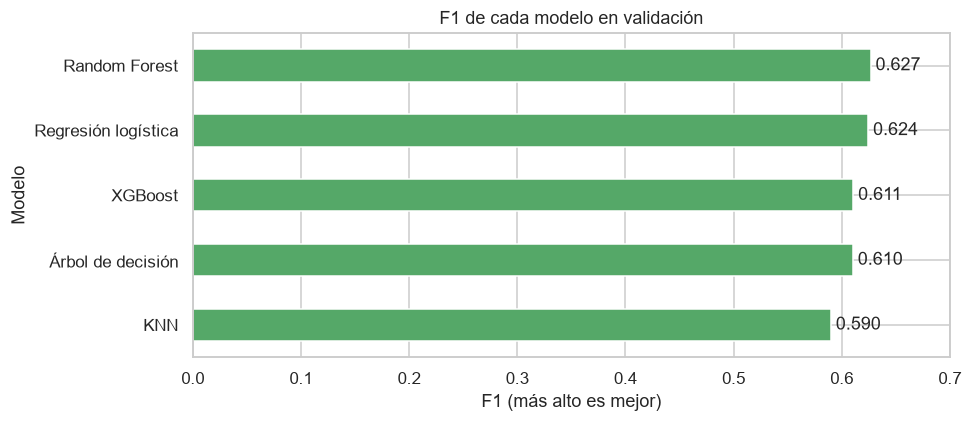

In [19]:
# Figura 2: comparación visual del F1 en validación
fig, ax = plt.subplots(figsize=(9, 4))  # figura con un solo gráfico
tabla_validacion["F1"].sort_values().plot.barh(ax=ax, color="#55A868")  # barras horizontales ordenadas por F1
ax.set_title("F1 de cada modelo en validación")
ax.set_xlabel("F1 (más alto es mejor)")
ax.set_xlim(0, 0.7)  # eje X fijo de 0 a 0.7
for i, valor in enumerate(tabla_validacion["F1"].sort_values()):  # escribe el valor de F1 al final de cada barra
    ax.text(valor, i, f" {valor:.3f}", va="center")
fig.tight_layout()  # acomoda el gráfico
plt.show()  # muestra la figura

In [20]:
# 15. Elegir el modelo con mayor F1 en validación
# Esta decisión se toma SIN mirar el conjunto de prueba.
nombre_elegido = tabla_validacion.index[0]  # la primera fila es el modelo con mayor F1
print(f"Modelo elegido: {nombre_elegido}")
print(f"F1 en validación: {tabla_validacion.loc[nombre_elegido, 'F1']:.3f}")

Modelo elegido: Random Forest
F1 en validación: 0.627


In [21]:
# 16. Evaluación final sobre el conjunto de prueba
# Se usa el modelo ya elegido. No se cambia nada después de ver este resultado.
modelos = {  # diccionario: nombre -> modelo ya entrenado (se reutiliza más adelante)
    "Regresión logística": modelo_lr,
    "KNN": modelo_knn,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
}

modelo_final = modelos[nombre_elegido]  # toma el modelo elegido en validación
pred_final = modelo_final.predict(X_test)  # primera y única predicción sobre el conjunto de prueba

# Métricas finales sobre datos que el modelo nunca vio
print(f"Modelo: {nombre_elegido}\n")
print(f"Recall    : {recall_score(y_test, pred_final):.3f}")
print(f"Precision : {precision_score(y_test, pred_final):.3f}")
print(f"F1        : {f1_score(y_test, pred_final):.3f}")
print(f"Accuracy  : {accuracy_score(y_test, pred_final):.3f}")

Modelo: Random Forest

Recall    : 0.778
Precision : 0.522
F1        : 0.624
Accuracy  : 0.752


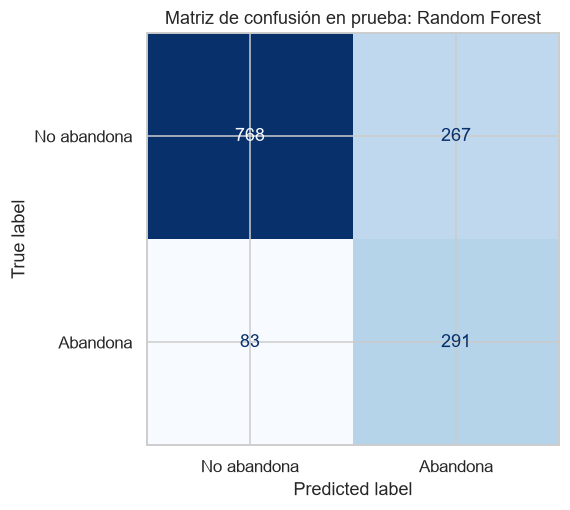

In [22]:
# Figura 3: matriz de confusión del modelo elegido
ConfusionMatrixDisplay.from_predictions(  # dibuja la matriz: aciertos y errores de cada clase
    y_test,
    pred_final,
    display_labels=["No abandona", "Abandona"],
    cmap="Blues",  # paleta de colores
    colorbar=False,  # sin barra de color lateral
)
plt.title(f"Matriz de confusión en prueba: {nombre_elegido}")  # título con el nombre del modelo
plt.tight_layout()  # acomoda el gráfico
plt.show()  # muestra la figura

In [23]:
# 17. Resumen final
resumen = tabla_validacion.copy()  # copia de la tabla de validación
resumen["Elegido"] = resumen.index == nombre_elegido  # marca con True al modelo elegido
print(f"Modelo elegido por F1 de validación: {nombre_elegido}")
print(f"F1 en prueba de ese modelo: {f1_score(y_test, pred_final):.3f}")
resumen.round(3)  # muestra la tabla con 3 decimales

Modelo elegido por F1 de validación: Random Forest
F1 en prueba de ese modelo: 0.624


,Recall,Precision,F1,Accuracy,Elegido
Modelo,,,,,
Random Forest,0.781,0.523,0.627,0.753,True
Regresión logística,0.789,0.517,0.624,0.748,False
XGBoost,0.775,0.503,0.611,0.737,False
Árbol de decisión,0.799,0.493,0.610,0.729,False
KNN,0.561,0.621,0.590,0.793,False


## Ampliación 2 – ROC-AUC de los cinco modelos
La rúbrica y las metas del proyecto incluyen el **ROC-AUC**, que mide qué tan bien el modelo separa a quienes abandonan de quienes permanecen, sin depender de un umbral. Se calcula con las probabilidades de los cinco modelos ya entrenados en las secciones 9 a 13, sin volver a entrenar.

In [24]:
# Ampliación 2: ROC-AUC en validación y prueba (modelos ya entrenados, sin reentrenar)
prob_val = {n: m.predict_proba(X_val)[:, 1] for n, m in modelos.items()}  # probabilidad de abandono (0 a 1) que da cada modelo en validación
prob_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}  # lo mismo sobre el conjunto de prueba

tabla_auc = pd.DataFrame(  # ROC-AUC: capacidad de separar a quienes abandonan de quienes permanecen
    {
        "ROC-AUC validación": {n: roc_auc_score(y_val, p) for n, p in prob_val.items()},
        "ROC-AUC prueba": {n: roc_auc_score(y_test, p) for n, p in prob_test.items()},
    }
).sort_values("ROC-AUC validación", ascending=False)  # ordena por ROC-AUC en validación
tabla_auc.round(3)  # muestra la tabla con 3 decimales

,ROC-AUC validación,ROC-AUC prueba
Random Forest,0.837,0.842
XGBoost,0.836,0.839
Regresión logística,0.836,0.843
Árbol de decisión,0.824,0.832
KNN,0.824,0.830


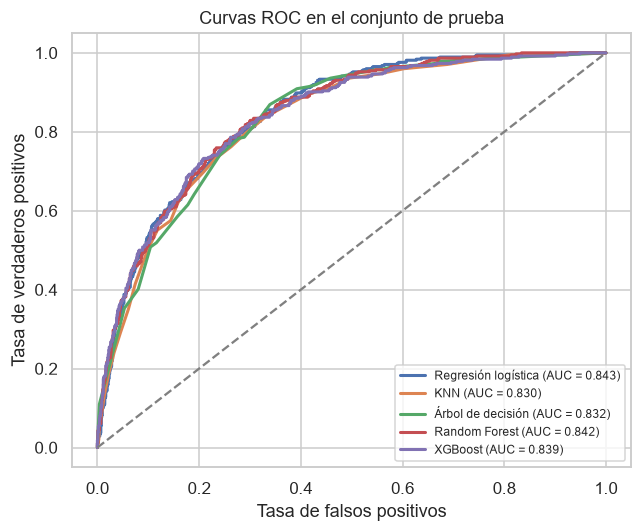

In [25]:
# Figura 4: curvas ROC en prueba
fig, ax = plt.subplots(figsize=(6, 5))  # figura con un solo gráfico
for nombre, p in prob_test.items():  # una curva por modelo
    fpr, tpr, _ = roc_curve(y_test, p)  # puntos de la curva: falsos positivos frente a verdaderos positivos
    ax.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {tabla_auc.loc[nombre, 'ROC-AUC prueba']:.3f})")  # dibuja la curva del modelo con su AUC en la leyenda
ax.plot([0, 1], [0, 1], "--", color="grey")  # línea de referencia: un modelo que adivina al azar
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")  # nombres de los ejes
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.legend(loc="lower right", fontsize=8)  # título y leyenda
fig.tight_layout()
plt.show()  # acomoda y muestra la figura

## Ampliación 3 – Validación cruzada (5 particiones)
Una sola partición de validación puede dar un resultado "con suerte". La validación cruzada repite la evaluación en 5 particiones distintas y entrega el promedio y la variación. Se usa el 80 % de los datos (entrenamiento + validación); **la prueba no interviene**.

In [26]:
# Ampliación 3: validación cruzada estratificada sobre entrenamiento + validación
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # 5 particiones que mantienen el % de abandono en cada una
metricas_cv = ["recall", "precision", "f1", "roc_auc", "accuracy"]  # métricas que se calculan en cada partición

filas_media, filas_texto = {}, {}  # promedios (números) y texto «promedio ± desviación»
for nombre, modelo in modelos.items():  # valida cada uno de los cinco modelos
    r = cross_validate(clone(modelo), X_resto, y_resto, cv=cv, scoring=metricas_cv)  # entrena y evalúa 5 veces con una copia sin entrenar; no usa el conjunto de prueba
    filas_media[nombre] = {m: r[f"test_{m}"].mean() for m in metricas_cv}  # promedio de cada métrica en las 5 particiones
    filas_texto[nombre] = {m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in metricas_cv}  # promedio ± desviación estándar (cuánto varía entre particiones)

tabla_cv_media = pd.DataFrame(filas_media).T  # tabla numérica (se usa para ordenar)
tabla_cv = pd.DataFrame(filas_texto).T.rename(  # tabla de texto; se renombran las columnas por nombre, sin depender del orden
    columns={"recall": "Recall", "precision": "Precision", "f1": "F1", "roc_auc": "ROC-AUC", "accuracy": "Accuracy"}
)
tabla_cv.loc[tabla_cv_media["roc_auc"].sort_values(ascending=False).index]  # muestra la tabla ordenada por ROC-AUC promedio

,Recall,Precision,F1,ROC-AUC,Accuracy
Random Forest,0.794 ± 0.019,0.529 ± 0.016,0.635 ± 0.014,0.847 ± 0.009,0.758 ± 0.012
Regresión logística,0.801 ± 0.038,0.517 ± 0.019,0.628 ± 0.023,0.846 ± 0.012,0.748 ± 0.015
XGBoost,0.799 ± 0.023,0.524 ± 0.013,0.633 ± 0.017,0.846 ± 0.011,0.754 ± 0.011
KNN,0.583 ± 0.022,0.621 ± 0.023,0.601 ± 0.021,0.835 ± 0.009,0.795 ± 0.011
Árbol de decisión,0.777 ± 0.036,0.511 ± 0.011,0.616 ± 0.011,0.829 ± 0.014,0.743 ± 0.008


## Ampliación 4 – Ajuste de hiperparámetros (regresión logística, Random Forest y XGBoost)
Los modelos de las secciones 9 a 13 usan valores fijos. Aquí se buscan mejores valores para los tres modelos del caso con `GridSearchCV` (5 particiones, métrica ROC-AUC) **usando solo el conjunto de entrenamiento**. La elección del modelo final de la sección 15 no se modifica; el ajuste se reporta como un análisis complementario.

In [27]:
# Ampliación 4: GridSearchCV sobre el conjunto de entrenamiento
# Con n_jobs=-1, scikit-learn 1.9 repite un aviso interno por cada combinación probada.
# Se silencia solo ese mensaje; ningún error ni aviso del análisis queda oculto.
warnings.filterwarnings("ignore", message=".*sklearn\\.utils\\.parallel\\.delayed.*")

mallas = {  # por cada modelo: (modelo base, valores de hiperparámetros a probar)
    "Regresión logística": (modelo_lr, {"modelo__C": [0.01, 0.1, 1, 10]}),  # C: fuerza de la regularización (más bajo = modelo más simple)
    "Random Forest": (modelo_rf, {"modelo__max_depth": [6, 8, 10], "modelo__min_samples_leaf": [3, 10, 20]}),  # profundidad máxima y mínimo de clientes por hoja
    "XGBoost": (modelo_xgb, {"modelo__n_estimators": [200, 300, 400], "modelo__learning_rate": [0.03, 0.05, 0.1], "modelo__max_depth": [3, 4, 5]}),  # número de árboles, tasa de aprendizaje y profundidad
}
modelos_ajustados, mejores = {}, {}  # guardan los mejores modelos y sus valores
for nombre, (base, malla) in mallas.items():  # busca los mejores valores para cada modelo
    gs = GridSearchCV(clone(base), malla, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)  # prueba todas las combinaciones con validación cruzada (5) y elige la de mayor ROC-AUC; usa solo el entrenamiento
    modelos_ajustados[nombre] = gs.best_estimator_  # guarda el modelo con los mejores valores
    mejores[nombre] = {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()}  # guarda los mejores valores (sin el prefijo «modelo__»)
    # Muestra los mejores valores y su ROC-AUC en validación cruzada
    print(f"{nombre:20s} mejores parámetros: {mejores[nombre]}  (ROC-AUC CV = {gs.best_score_:.3f})")

Regresión logística  mejores parámetros: {'C': 10}  (ROC-AUC CV = 0.848)
Random Forest        mejores parámetros: {'max_depth': 10, 'min_samples_leaf': 20}  (ROC-AUC CV = 0.850)
XGBoost              mejores parámetros: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}  (ROC-AUC CV = 0.847)


In [28]:
# Comparación: modelo con valores fijos vs. modelo ajustado (validación) y resultado informativo en prueba
filas = []  # aquí se guarda una fila por cada versión de cada modelo
for nombre, ajustado in modelos_ajustados.items():  # compara cada modelo ajustado con su versión original
    base = modelos[nombre]  # versión con valores fijos
    for etiqueta, m in [("fijos", base), ("ajustado", ajustado)]:  # evalúa las dos versiones
        pv, pt = m.predict(X_val), m.predict(X_test)  # predicciones en validación (pv) y en prueba (pt)
        filas.append({  # guarda las métricas de esta versión
            "Modelo": nombre,
            "Versión": etiqueta,
            "F1 val": f1_score(y_val, pv),
            "ROC-AUC val": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]),
            "Recall prueba": recall_score(y_test, pt),
            "F1 prueba": f1_score(y_test, pt),
            "ROC-AUC prueba": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
        })
tabla_ajuste = pd.DataFrame(filas).set_index(["Modelo", "Versión"])  # tabla con Modelo y Versión como índice
tabla_ajuste.round(3)  # muestra la tabla con 3 decimales

F1 val  ROC-AUC val  Recall prueba  F1 prueba  ROC-AUC prueba
Modelo              Versión                                                                
Regresión logística fijos      0.624        0.836          0.783      0.614           0.843
                    ajustado   0.620        0.837          0.786      0.616           0.842
Random Forest       fijos      0.627        0.837          0.778      0.624           0.842
                    ajustado   0.621        0.838          0.797      0.625           0.844
XGBoost             fijos      0.611        0.836          0.791      0.623           0.839
                    ajustado   0.617        0.839          0.805      0.623           0.844

## Ampliación 5 – Cumplimiento de las metas del proyecto (conjunto de prueba)
Metas definidas en el informe: **ROC-AUC ≥ 0.80**, **recall ≥ 0.75**, **F1 ≥ 0.60** y **accuracy superior** a la del modelo que siempre dice «no abandona».

Esta tabla es **descriptiva**: comprueba las metas sobre prueba una vez terminado el análisis y **no** se usa para elegir modelo. La elección sigue siendo la de la sección 15 (mayor F1 en validación).

In [29]:
# Ampliación 5: metas sobre el conjunto de prueba
acc_base = 1 - y_test.mean()  # accuracy del modelo que siempre dice «no abandona»
candidatos = dict(modelos)  # los cinco modelos originales...
candidatos.update({f"{n} (ajustado)": m for n, m in modelos_ajustados.items()})  # ...más los tres modelos ajustados

filas = {}  # aquí se guarda una fila por modelo
for nombre, m in candidatos.items():  # evalúa cada modelo con las cuatro metas
    pred = m.predict(X_test)  # predicción en prueba
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])  # ROC-AUC en prueba
    rec, f1v, acc = recall_score(y_test, pred), f1_score(y_test, pred), accuracy_score(y_test, pred)  # recall, F1 y accuracy en prueba
    filas[nombre] = {  # cada columna «¿...?» indica si se cumple la meta (Sí/No)
        "ROC-AUC": round(auc, 3),
        "¿≥ 0.80?": "Sí" if auc >= 0.80 else "No",
        "Recall": round(rec, 3),
        "¿≥ 0.75?": "Sí" if rec >= 0.75 else "No",
        "F1": round(f1v, 3),
        "¿≥ 0.60?": "Sí" if f1v >= 0.60 else "No",
        "Accuracy": round(acc, 3),
        f"¿> {acc_base:.3f}?": "Sí" if acc > acc_base else "No",
    }
tabla_metas = pd.DataFrame(filas).T  # la transpuesta deja un modelo por fila
tabla_metas

,ROC-AUC,¿≥ 0.80?,Recall,¿≥ 0.75?,F1,¿≥ 0.60?,Accuracy,¿> 0.735?
Regresión logística,0.843,Sí,0.783,Sí,0.614,Sí,0.739,Sí
KNN,0.83,Sí,0.575,No,0.583,No,0.781,Sí
Árbol de decisión,0.832,Sí,0.783,Sí,0.614,Sí,0.739,Sí
Random Forest,0.842,Sí,0.778,Sí,0.624,Sí,0.752,Sí
XGBoost,0.839,Sí,0.791,Sí,0.623,Sí,0.745,Sí
Regresión logística (ajustado),0.842,Sí,0.786,Sí,0.616,Sí,0.74,Sí
Random Forest (ajustado),0.844,Sí,0.797,Sí,0.625,Sí,0.746,Sí
XGBoost (ajustado),0.844,Sí,0.805,Sí,0.623,Sí,0.741,Sí


## Ampliación 6 – ¿Qué variables explican el abandono?
Importancia de variables en Random Forest (el modelo elegido en la sección 15) y en XGBoost, y coeficientes de la regresión logística.
Son **asociaciones, no causas**. En la regresión logística hay colinealidad entre `MonthlyCharges` y los servicios contratados, por lo que cada coeficiente no debe leerse de forma aislada.

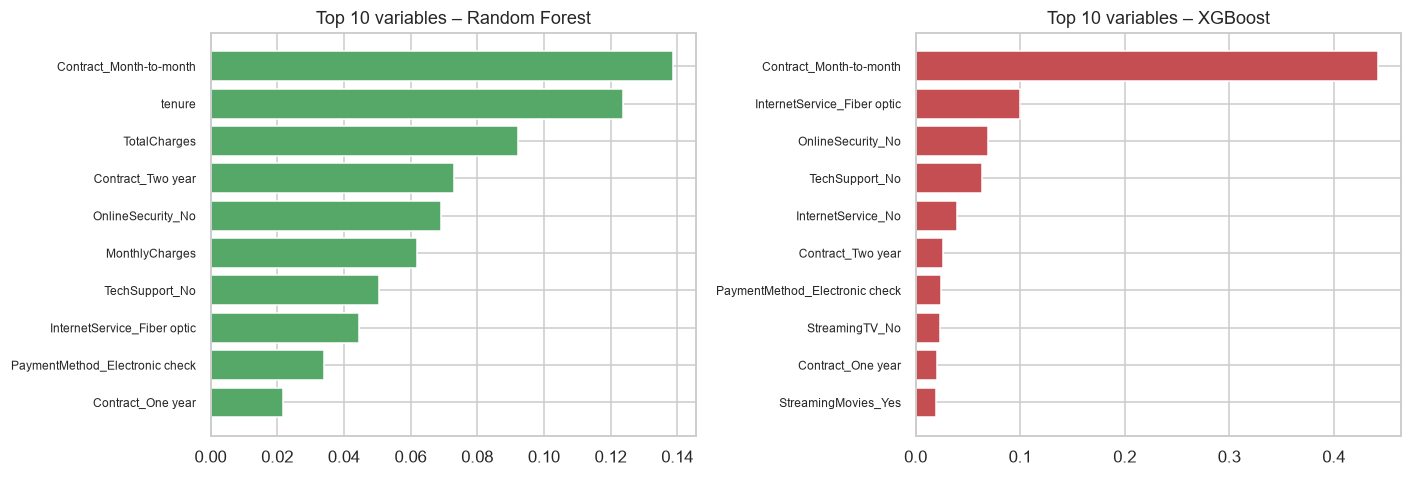

Coeficientes de la regresión logística con mayor efecto (+ más riesgo, − menos riesgo):
Contract_Month-to-month           0.741
InternetService_Fiber optic       0.595
TotalCharges                      0.558
StreamingTV_Yes                   0.226
PaymentMethod_Electronic check    0.222
StreamingMovies_Yes               0.198
tenure                           -1.222
Contract_Two year                -0.852
InternetService_DSL              -0.535
MonthlyCharges                   -0.396
MultipleLines_No                 -0.243
PaperlessBilling_No              -0.218


In [30]:
# Ampliación 6 / Figura 5: importancia de variables (Random Forest y XGBoost) y coeficientes
def nombres_variables(pipeline):  # nombres de las columnas después del preprocesamiento (incluye las columnas del one-hot)
    return [n.split("__", 1)[1] for n in pipeline.named_steps["preprocesador"].get_feature_names_out()]


imp_rf = pd.Series(modelo_rf.named_steps["modelo"].feature_importances_, index=nombres_variables(modelo_rf)).sort_values(ascending=False)  # importancia de cada variable según Random Forest (suman 1)
imp_xgb = pd.Series(modelo_xgb.named_steps["modelo"].feature_importances_, index=nombres_variables(modelo_xgb)).sort_values(ascending=False)  # importancia de cada variable según XGBoost
coef_lr = pd.Series(modelo_lr.named_steps["modelo"].coef_[0], index=nombres_variables(modelo_lr))  # coeficientes de la regresión logística (positivo = más riesgo, negativo = menos riesgo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))  # dos gráficos: Random Forest y XGBoost
for ax, serie, titulo, color in [(axes[0], imp_rf, "Random Forest", "#55A868"), (axes[1], imp_xgb, "XGBoost", "#C44E52")]:  # dibuja el top 10 de cada modelo
    s = serie.head(10)[::-1]  # las 10 más importantes, invertidas para que la mayor quede arriba
    ax.barh(s.index, s.values, color=color)  # barras horizontales
    ax.set_title(f"Top 10 variables – {titulo}")
    ax.tick_params(axis="y", labelsize=8)  # letra más pequeña para los nombres de variables
fig.tight_layout()  # acomoda los dos gráficos
plt.show()  # muestra la figura

# Los 6 coeficientes más altos y los 6 más bajos
print("Coeficientes de la regresión logística con mayor efecto (+ más riesgo, − menos riesgo):")
print(pd.concat([coef_lr.sort_values(ascending=False).head(6), coef_lr.sort_values().head(6)]).round(3).to_string())

## Ampliación 7 – Resumen final

In [31]:
# Ampliación 7: resumen con los resultados calculados en este notebook
elegido_auc_prueba = tabla_auc.loc[nombre_elegido, "ROC-AUC prueba"]  # ROC-AUC del modelo elegido en el conjunto de prueba
# Resumen final con los resultados calculados arriba
print(f"Modelo elegido (por F1 en validación): {nombre_elegido}")
print(f"  ROC-AUC en prueba : {elegido_auc_prueba:.3f}")
print(f"  Recall en prueba  : {recall_score(y_test, pred_final):.3f}")
print(f"  F1 en prueba      : {f1_score(y_test, pred_final):.3f}")
print(f"  Accuracy en prueba: {accuracy_score(y_test, pred_final):.3f} (referencia sin modelo: {acc_base:.3f})")
cumple = tabla_metas.loc[nombre_elegido, [c for c in tabla_metas.columns if c.startswith("¿")]].eq("Sí").all()  # True solo si el modelo cumple las cuatro metas
print(f"  ¿Cumple las cuatro metas? {'Sí' if cumple else 'No'}")
print("\nVariables con mayor importancia en Random Forest:", ", ".join(imp_rf.head(5).index))

Modelo elegido (por F1 en validación): Random Forest
  ROC-AUC en prueba : 0.842
  Recall en prueba  : 0.778
  F1 en prueba      : 0.624
  Accuracy en prueba: 0.752 (referencia sin modelo: 0.735)
  ¿Cumple las cuatro metas? Sí

Variables con mayor importancia en Random Forest: Contract_Month-to-month, tenure, TotalCharges, Contract_Two year, OnlineSecurity_No
